> Notebook-friendly copy of `part-III/6.3-land-cover-classification-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch", "torchmetrics": "torchmetrics"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 6.3) (Exercise) Land Cover Classification
![EuroSAT overview image](https://raw.githubusercontent.com/phelber/EuroSAT/master/eurosat_overview_small.jpg)

This notebook is converted from the source: https://www.coursera.org/learn/getting-started-with-tensor-flow2

**🎯 Learning objectives**

- Construct CNNs that classify EuroSAT images into one of 10 land use classes
- Save and load trained models
- Improve the performance of the model

**Land Cover Classification** aims to automatically provide labels describing the represented physical land type or how a land area is used (e.g., residential, industrial).   

**Convolutional Neural Networks (CNNs)**,  the state of-the-art image classification method in computer vision and machine learning, have been reported to be suitable for the classification of remotely sensed
images.

However, the classification of remotely sensed images is a challenging task, particularly due to the lack of reliably labeled ground truth datasets.

The [EuroSAT dataset](https://github.com/phelber/EuroSAT) provides large quantity of training data for this purpose. It consists of 27000 labelled Sentinel-2 satellite images of different land uses: residential, industrial, highway, river, forest, pasture, herbaceous vegetation, annual crop, permanent crop and sea/lake.

For a reference, see the following papers:
- Eurosat: A novel dataset and deep learning benchmark for land use and land cover classification. Patrick Helber, Benjamin Bischke, Andreas Dengel, Damian Borth. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 2019.
- Introducing EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification. Patrick Helber, Benjamin Bischke, Andreas Dengel. 2018 IEEE International Geoscience and Remote Sensing Symposium, 2018.



---




You can **create your own code** by following each question **or complete the code with blanks**.


---

In [2]:
# Run this cell first to import all required packages.
import torch
import torch.nn as nn
from collections import OrderedDict  # dictionnaire ordonné -> permet de NOMMER les couches de nn.Sequential

In [3]:
import torchvision

In [4]:
import torchmetrics
from sklearn.model_selection import train_test_split  # pour couper le jeu de test en validation + test

In [5]:
import os
import glob
import tarfile
import pooch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# If you would like to make further imports from torch or torchvision, add them here

## Data Setup

Using the EuroSAT dataset which consists of 27000 images and labels might use too much memory, thus we use a smaller subset of the original dataset - 4000 training images and 1000 testing images with roughly equal numbers of each class.

In [6]:
# Run this cell to fetch and reassemble the dataset
chunk_suffixes = ["aa", "ab"]
chunk_hashes = {
    "aa": "ce9f73e68261a010956eeb73876f047f35a25986b037694cd08cc0a837418f3c",
    "ab": "b87e1a0b9da3e69579723103a4934d1b0bbb518d3d1a0d11f51b5ff75db56e25",
}
cache_dir = pooch.os_cache("mlees")
chunk_paths = [
    pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-III/data_cnn.zip.part{suffix}",
        known_hash=f"sha256:{chunk_hashes[suffix]}",
        fname=f"data_cnn.zip.part{suffix}",
        path=cache_dir,
    )
    for suffix in chunk_suffixes
]

In [7]:
data_cnn_archive = os.path.join(cache_dir, "data_cnn.zip")
if not os.path.exists(data_cnn_archive):
    with open(data_cnn_archive, "wb") as out_f:
        for chunk_path in chunk_paths:
            with open(chunk_path, "rb") as in_f:
                out_f.write(in_f.read())
    import zipfile
    with zipfile.ZipFile(data_cnn_archive) as z:
        z.extractall(cache_dir)

In [8]:
data_cnn_dir = os.path.join(cache_dir, "data_cnn")  # dossier contenant les fichiers .npy

In [9]:
# Import the Eurosat data
def load_eurosat_data():
    x_train = np.load(os.path.join(data_cnn_dir, 'x_train.npy'))  # 4000 images d'entraînement (64x64x3)
    y_train = np.load(os.path.join(data_cnn_dir, 'y_train.npy'))
    x_val  = np.load(os.path.join(data_cnn_dir, 'x_test.npy'))
    y_val  = np.load(os.path.join(data_cnn_dir, 'y_test.npy'))
    return (x_train, y_train), (x_val, y_val)

In [10]:
(X_train, y_train), (X_val_test, y_val_test) = load_eurosat_data()
X_val, X_test, y_val, y_test = train_test_split(X_val_test, y_val_test, test_size=0.5, random_state=42)  # 50/50 : 500 images de validation, 500 de test

In [11]:
# Normalize data, move the channel dimension to PyTorch's expected position
# (channels first), and convert everything to tensors
def to_tensor(X, y):
    X = torch.tensor(X / 255.0, dtype=torch.float32).permute(0, 3, 1, 2)  # /255 -> pixels entre 0 et 1 ; permute : (N, H, W, C) -> (N, C, H, W), format PyTorch
    y = torch.tensor(y, dtype=torch.long).reshape(-1)  # (N, 1) -> (N,)
    return X, y

In [12]:
X_train, y_train = to_tensor(X_train, y_train)
X_val, y_val = to_tensor(X_val, y_val)
X_test, y_test = to_tensor(X_test, y_test)

Since PyTorch has no `.compile()`/`.fit()`/`.evaluate()`, we'll define three small reusable helpers before building any models — one to train a model for a number of epochs (optionally with callbacks and a validation set), one to evaluate a model on a dataset, and a `History` class that mimics Keras's `history.history` dict-of-lists so the rest of this notebook can stay close to the original.

In [13]:
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU si disponible (ajouté pour accélérer)
print("Device:", device)

class History:
    def __init__(self):
        self.history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}  # stocke les courbes d'apprentissage, époque par époque

Device: cuda


In [14]:
def evaluate_model(model, X, y, batch_size=32):  # renvoie [loss moyenne, précision] sur un jeu de données
    model.eval()
    model.to(device); accuracy.to(device)  # modèle et métrique sur GPU/CPU
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=batch_size)
    losses = []
    accuracy.reset()
    with torch.no_grad():  # pas de gradients : on évalue seulement
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)  # batch sur le même device que le modèle
            y_pred = model(X_batch)
            losses.append(loss_fn(y_pred, y_batch).item())
            accuracy.update(y_pred, y_batch)
    return [np.mean(losses), accuracy.compute().item()]

In [15]:
def train_model(model, X, y, epochs, validation_data=None, callbacks=None, verbose=1):  # boucle d'entraînement réutilisable (équivalent de .fit() de Keras)
    callbacks = callbacks or []
    model.to(device); accuracy.to(device)  # modèle et métrique sur GPU/CPU (avant de créer l'optimiseur)
    optimizer = optimizer_class(model.parameters())  # crée l'optimiseur (ex. Adam) lié aux poids de CE modèle
    history = History()
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=32, shuffle=True)  # batchs de 32, mélangés

    for epoch in range(epochs):
        model.train()
        train_losses = []
        accuracy.reset()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()  # remet les gradients à 0
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)  # batch sur le même device que le modèle
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            loss.backward()  # rétropropagation
            optimizer.step()  # mise à jour des poids
            train_losses.append(loss.item())
            accuracy.update(y_pred, y_batch)

        logs = {"loss": np.mean(train_losses), "accuracy": accuracy.compute().item()}
        history.history["loss"].append(logs["loss"])
        history.history["accuracy"].append(logs["accuracy"])

        report = f"Epoch {epoch + 1}/{epochs} - loss: {logs['loss']:.4f} - accuracy: {logs['accuracy']:.4f}"
        if validation_data is not None:
            val_loss, val_accuracy = evaluate_model(model, *validation_data)
            logs["val_loss"], logs["val_accuracy"] = val_loss, val_accuracy
            history.history["val_loss"].append(val_loss)
            history.history["val_accuracy"].append(val_accuracy)
            report += f" - val_loss: {val_loss:.4f} - val_accuracy: {val_accuracy:.4f}"
        if verbose:
            print(report)

        stop_training = False
        for callback in callbacks:
            if callback.on_epoch_end(epoch, model, logs) == "stop":  # appelle chaque callback à la fin de l'époque
                stop_training = True
        if stop_training:
            break

    return history

## Q1 Build a CNN `model1` to classify Eurosat data.

Let's construct a CNN called `model1` using `nn.Sequential`, according to the following specifications:

* The first layer should be a `Conv2d` layer with 16 filters, a 3x3 kernel size, and 'same' padding. Name this layer 'conv_1'.
* Follow it with a `ReLU` activation, named 'relu_1'.
* The third layer should also be a `Conv2d` layer with 8 filters, a 3x3 kernel size, and 'same' padding. Name this layer 'conv_2'.
* Follow it with a `ReLU` activation, named 'relu_2'.
* The fifth layer should be a `MaxPool2d` layer with a pooling window size of 8x8. Name this layer 'pool_1'.
* The sixth layer should be a `Flatten` layer, named 'flatten'.
* The seventh layer should be a `Linear` layer with 32 units, followed by a `ReLU` activation. Name these layers 'dense_1' and 'relu_3'.
* The final layer should be a `Linear` layer with 10 units and no activation (unlike Keras, `nn.CrossEntropyLoss` expects raw logits, not softmax probabilities). Name this layer 'dense_2'.

*Hint 1: Unlike `keras.models.Sequential`, `nn.Sequential` doesn't have an `.add()` method — but if you pass it an [`OrderedDict`](https://docs.python.org/3/library/collections.html#collections.OrderedDict) of `(name, layer)` pairs, you get the same named-layer access (`model1.conv_1`, etc.) that Keras's `name=` argument gives you.*

*Hint 2: `nn.Conv2d` needs an explicit number of input channels — 3 for the first layer (RGB), and `conv_2`'s input channels equal `conv_1`'s output channels.*

*Hint 3: As in the artificial-neural-networks and deep-computer-vision exercises, [`nn.LazyLinear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html) can save you from computing the flattened size by hand.*

In [16]:
# Assign value to input_shape variable (channels, height, width)
input_shape = X_train.shape[1:]  # (canaux, hauteur, largeur) = (3, 64, 64) ; [1:] enlève la dimension 'nb d'images'

In [17]:
# Build the model, one named layer at a time
model1 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),  # 3 canaux RVB -> 16 filtres 3x3 ; 'same' garde la taille 64x64
    ("relu_1", nn.ReLU()),  # activation max(0, x)
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),  # entrée = 16 (sortie de conv_1) -> 8 filtres
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),  # max de chaque carré 8x8 -> 64x64 devient 8x8
    ("flatten", nn.Flatten()),  # 8 cartes x 8 x 8 -> vecteur de 512 valeurs
    ("dense_1", nn.LazyLinear(32)),  # couche dense de 32 neurones (taille d'entrée déduite automatiquement)
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),  # 10 sorties = 10 classes d'occupation du sol (logits, pas de softmax)
]))

In [18]:
# Run one batch through the model to materialize the LazyLinear layers
model1(X_train[:1])  # passe 1 image dans le réseau pour initialiser les LazyLinear

tensor([[ 0.1117, -0.1182,  0.2367, -0.1983,  0.0839, -0.1736, -0.0625, -0.0139,
         -0.1106, -0.0770]], grad_fn=<AddmmBackward0>)

❓❓❓ Do you have a model of the following structure?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model1-summary-reference.jpg?raw=1'> </center>

*(This screenshot is from the original Keras version of this exercise — `print(model1)` will show a differently formatted, but structurally equivalent, layer list.)*

## Q2 Set up `model1`'s loss function, optimizer, and an evaluation metric.

* Use the Adam optimiser, cross entropy loss function, and a single accuracy metric.

In [19]:
loss_fn = nn.CrossEntropyLoss() # Set the loss function
optimizer_class = torch.optim.Adam # Set the optimizer class (train_model binds it to each model's parameters)
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10) # Set the evaluation metric

## Q3 Evaluate the initial accuracy of `model1`: Is the initial accuracy of the model as you have expected?

In [20]:
# Calculate its initialised test accuracy
test_loss, test_acc = evaluate_model(model1, X_test, y_test)  # modèle PAS encore entraîné (poids aléatoires) -> ~10 % attendu (1 chance sur 10)
print('Test accuracy: {acc:0.3f}'.format(acc=test_acc))

Test accuracy: 0.098


❓❓❓ Does your model have a similar initial accuracy & why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-initial-accuracy-reference.jpg?raw=1'> </center>

## Q4 Train `model1` with 15 epochs, store the result in variable 'history';
* Store the fitting result in a variable history;

In [21]:
epochs = 15  # 15 passages complets sur les 4000 images

history = train_model(model1, X_train, y_train,  # entraîne model1 sur le train

                    epochs=epochs,

                    validation_data=(X_val, y_val))  # mesure loss/précision sur la validation à chaque époque

Epoch 1/15 - loss: 1.9754 - accuracy: 0.2360 - val_loss: 1.7151 - val_accuracy: 0.2840
Epoch 2/15 - loss: 1.5330 - accuracy: 0.4140 - val_loss: 1.4946 - val_accuracy: 0.4460
Epoch 3/15 - loss: 1.3587 - accuracy: 0.4670 - val_loss: 1.3510 - val_accuracy: 0.4720
Epoch 4/15 - loss: 1.2575 - accuracy: 0.5232 - val_loss: 1.2679 - val_accuracy: 0.5620
Epoch 5/15 - loss: 1.1943 - accuracy: 0.5590 - val_loss: 1.2499 - val_accuracy: 0.5180
Epoch 6/15 - loss: 1.1177 - accuracy: 0.5900 - val_loss: 1.1656 - val_accuracy: 0.5700
Epoch 7/15 - loss: 1.0841 - accuracy: 0.6045 - val_loss: 1.1649 - val_accuracy: 0.5740
Epoch 8/15 - loss: 1.0428 - accuracy: 0.6122 - val_loss: 1.0780 - val_accuracy: 0.6360
Epoch 9/15 - loss: 1.0026 - accuracy: 0.6277 - val_loss: 1.0535 - val_accuracy: 0.6060
Epoch 10/15 - loss: 0.9651 - accuracy: 0.6482 - val_loss: 1.0565 - val_accuracy: 0.6280
Epoch 11/15 - loss: 0.9526 - accuracy: 0.6535 - val_loss: 1.1011 - val_accuracy: 0.6020
Epoch 12/15 - loss: 0.9072 - accuracy: 0.

❓❓❓ Do you have similar print output?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-training-output-reference.jpg?raw=1'> </center>

*(Again, expect a differently formatted but comparable progress report — there's no Keras-style progress bar here.)*

## Q5 Evaluate the accuracy of fitted `model1`, plot training, validation set loss and accuracy, and print the model's structure

* Evaluate the fitted model
    * What's the test accuracy after training the model? Does it improve from the initialization?
* Print the model's structure

In [22]:
# Calculate the test accuracy
score = evaluate_model(model1, X_test, y_test)  # score = [loss, précision] sur le test
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.654


❓❓❓ Do you have similar test accuracy?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-test-accuracy-reference.jpg?raw=1'> </center>

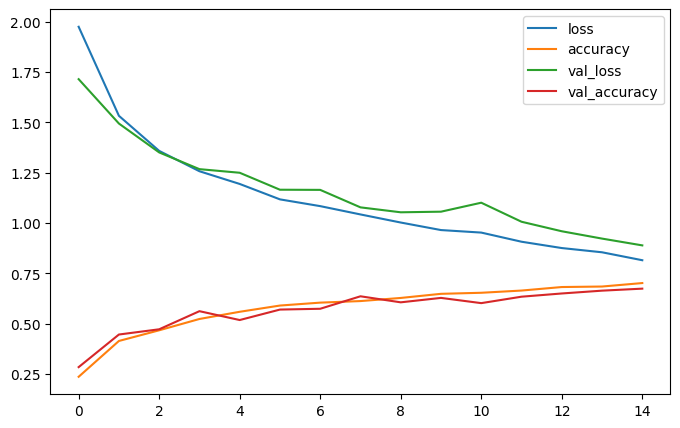

In [23]:
# Plot training, validation set loss and accuracy
pd.DataFrame(history.history).plot(figsize=(8,5))  # 1 courbe par colonne : loss, accuracy, val_loss, val_accuracy
plt.show()

❓❓❓ Do you have a similar plot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-loss-accuracy-plot-reference.png?raw=1'> </center>

In [24]:
# Print the model's structure
print(model1)  # liste des couches nommées

Sequential(
  (conv_1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu_1): ReLU()
  (conv_2): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu_2): ReLU()
  (pool_1): MaxPool2d(kernel_size=(8, 8), stride=(8, 8), padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense_1): Linear(in_features=512, out_features=32, bias=True)
  (relu_3): ReLU()
  (dense_2): Linear(in_features=32, out_features=10, bias=True)
)


❓❓❓ Do you have a similar structure?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model-plot-reference.jpg?raw=1'> </center>

*(This reference was generated with Keras's `plot_model` utility, which has no PyTorch equivalent — `print(model)` gives you the same layer-by-layer information as text instead of a diagram.)*

## Q6 Create two callbacks to save the model weights at each epoch and the best validation accuracy epoch

1. `checkpoint_every_epoch`: a callback that saves the model weights every epoch during training;
2. `checkpoint_best_only`: a callback that saves only the weights with the highest validation accuracy.

*Hint 1: Since `train_model` calls each callback's `on_epoch_end(epoch, model, logs)` method after every epoch, a callback here is just a small class with that one method — `logs` is the same dict of `"loss"`/`"accuracy"`/`"val_loss"`/`"val_accuracy"` values printed for that epoch.*

*Hint 2: Use [`torch.save(model.state_dict(), path)`](https://docs.pytorch.org/docs/stable/generated/torch.save.html) to save weights — there's no PyTorch equivalent of Keras's `ModelCheckpoint`, so both callbacks save with plain `torch.save()`.*

In [25]:
# A callback that saves the model weights at the end of every epoch, into a
# directory called 'checkpoints_every_epoch', with filenames like
# 'checkpoint_000.pt', 'checkpoint_001.pt', etc. (the epoch number, formatted
# to three digits)
class CheckpointEveryEpoch:
    def __init__(self, dirpath):
        self.dirpath = dirpath
        os.makedirs(dirpath, exist_ok=True)

    def on_epoch_end(self, epoch, model, logs):
        path = os.path.join(self.dirpath, f"checkpoint_{epoch:03d}.pt")  # :03d -> numéro sur 3 chiffres (000, 001...)
        torch.save(model.state_dict(), path)  # state_dict = dictionnaire de tous les poids du modèle

checkpoint_every_epoch = CheckpointEveryEpoch(dirpath="checkpoints_every_epoch")

In [26]:
# A callback that saves the model weights only when they reach the highest
# validation accuracy so far, into a file called
# 'checkpoints_best_only/checkpoint.pt'
class CheckpointBestOnly:
    def __init__(self, filepath, monitor="val_accuracy"):
        self.filepath = filepath
        self.monitor = monitor
        self.best = -np.inf
        os.makedirs(os.path.dirname(filepath), exist_ok=True)

    def on_epoch_end(self, epoch, model, logs):
        if logs[self.monitor] > self.best:  # meilleure précision de validation jusqu'ici ?
            self.best = logs[self.monitor]  # nouveau record
            torch.save(model.state_dict(), self.filepath)  # écrase le fichier -> ne garde que le MEILLEUR

In [27]:
checkpoint_best_only = CheckpointBestOnly(filepath=os.path.join("checkpoints_best_only", "checkpoint.pt"),
                                          monitor="val_accuracy")  # critère surveillé

## Q7 Build a CNN `model` with the same initial structure as `model1` and train for 15 epochs using the callbacks from Q6

Now, you will train the model using the two callbacks you created. If you created the callbacks correctly, two things should happen:
- At the end of every epoch, the model weights are saved into a directory called `checkpoints_every_epoch`
- At the end of every epoch, the model weights are saved into a directory called `checkpoints_best_only` **only** if those weights lead to the highest validation accuracy

You should then have two directories:
- A directory called `checkpoints_every_epoch` containing filenames that include `checkpoint_000.pt`, `checkpoint_001.pt`, etc, with the numbers corresponding to the epoch
- A directory called `checkpoints_best_only` containing a single `checkpoint.pt` file, containing only the weights leading to the highest validation accuracy

In [28]:
# Create a model with the same initial structure as model1 again from scratch
model = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model(X_train[:1])

tensor([[ 7.7804e-02,  1.6474e-01,  1.8252e-02,  1.4853e-01,  7.6310e-02,
          1.0865e-01, -1.4890e-02,  7.8231e-06, -1.2494e-01, -2.4985e-03]],
       grad_fn=<AddmmBackward0>)

In [29]:
# Train model using the callbacks you just created with 15 epochs

callbacks = [checkpoint_every_epoch, checkpoint_best_only]  # les 2 callbacks appelés à chaque fin d'époque
history = train_model(model, X_train, y_train, epochs=15, validation_data=(X_val, y_val), callbacks=callbacks)

Epoch 1/15 - loss: 1.9982 - accuracy: 0.2450 - val_loss: 1.7067 - val_accuracy: 0.3880
Epoch 2/15 - loss: 1.5426 - accuracy: 0.4173 - val_loss: 1.5052 - val_accuracy: 0.3900
Epoch 3/15 - loss: 1.3983 - accuracy: 0.4815 - val_loss: 1.3829 - val_accuracy: 0.4800
Epoch 4/15 - loss: 1.2949 - accuracy: 0.5255 - val_loss: 1.4309 - val_accuracy: 0.4340
Epoch 5/15 - loss: 1.2539 - accuracy: 0.5253 - val_loss: 1.3071 - val_accuracy: 0.4900
Epoch 6/15 - loss: 1.1960 - accuracy: 0.5410 - val_loss: 1.2371 - val_accuracy: 0.5060
Epoch 7/15 - loss: 1.1437 - accuracy: 0.5750 - val_loss: 1.2349 - val_accuracy: 0.5080
Epoch 8/15 - loss: 1.0970 - accuracy: 0.5922 - val_loss: 1.2256 - val_accuracy: 0.5460
Epoch 9/15 - loss: 1.0814 - accuracy: 0.5985 - val_loss: 1.1540 - val_accuracy: 0.5860
Epoch 10/15 - loss: 1.0465 - accuracy: 0.6097 - val_loss: 1.1182 - val_accuracy: 0.5580
Epoch 11/15 - loss: 1.0134 - accuracy: 0.6180 - val_loss: 1.0769 - val_accuracy: 0.6000
Epoch 12/15 - loss: 1.0118 - accuracy: 0.

❓❓❓ Do you have similar print output?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-checkpoint-training-output-reference.jpg?raw=1'> </center>

## Q8 Create new models `model_last_epoch` and `model_best_epoch` with model1's initial structure; load weights from the latest saved epoch and the saved epoch with the highest validation accuracy respectively

Now you will use the weights you just saved in a fresh model. You should load into two freshly instantiated model instances:
- `model_last_epoch` should contain the weights from the latest saved epoch
- `model_best_epoch` should contain the weights from the saved epoch with the highest validation accuracy

*Hint: `glob.glob("checkpoints_every_epoch/*.pt")` gives you every saved checkpoint path; sorting that list gives you the latest one at the end (since the filenames are zero-padded).*

In [30]:
# Create a new CNN with same structure as model1
model_last_epoch = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model_last_epoch(X_train[:1])

tensor([[-0.1179,  0.1490,  0.1874,  0.0828,  0.0175,  0.0405, -0.2076,  0.1588,
          0.0122, -0.0101]], grad_fn=<AddmmBackward0>)

In [31]:
# Load the weights from the last training epoch.
latest_checkpoint = sorted(glob.glob("checkpoints_every_epoch/*.pt"))[-1]  # liste tous les fichiers, triés ; [-1] = le dernier (dernière époque)
model_last_epoch.load_state_dict(torch.load(latest_checkpoint, weights_only=True))  # charge les poids dans le modèle vide

<All keys matched successfully>

In [32]:
# Create a new CNN with same structure as model1
model_best_epoch = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model_best_epoch(X_train[:1])

tensor([[ 0.1174,  0.1627,  0.1211,  0.0599, -0.1230,  0.0602,  0.0643, -0.1769,
          0.0617, -0.0988]], grad_fn=<AddmmBackward0>)

In [33]:
# Load the weights leading to the highest validation accuracy.
model_best_epoch.load_state_dict(torch.load("checkpoints_best_only/checkpoint.pt", weights_only=True))  # poids de la meilleure époque

<All keys matched successfully>

In [34]:
# Verify the validation accuracy of the last and the best model.

score = evaluate_model(model_last_epoch, X_val, y_val)  # précision de validation avec les poids de la dernière époque
print('Model validation accuracy with last epoch weights: {acc:0.3f}'.format(acc=score[1]))
print('')

score = evaluate_model(model_best_epoch, X_val, y_val)  # doit être >= à celle de la dernière époque
print('Model validation accuracy with best epoch weights: {acc:0.3f}'.format(acc=score[1]))

Model validation accuracy with last epoch weights: 0.618

Model validation accuracy with best epoch weights: 0.618


❓❓❓ Are the saved models' validation accuracy as expected?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-checkpoint-accuracy-reference.jpg?raw=1'> </center>

## Q9 Explore to improve the model performance by trying to reduce the bias: design and train a model2
* For example, train a CNN called model2, which has the same structure as model1, but with more convolution units: `conv_1` has 32 units, `conv_2` has 64 units, `dense_1` with 256 units

❓❓❓
* Does the model performance improve?
* What are other potential strategies to improve model performance by reducing the bias?

In [35]:
# Build model2 with the same structure as model1, but change the number of
# filters in conv_1 to 32 and conv_2 to 64, and dense_1 to 256 units.
model2 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 32, kernel_size=3, padding="same")),  # 32 filtres au lieu de 16 -> modèle plus puissant (réduit le BIAIS)
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(32, 64, kernel_size=3, padding="same")),  # 64 filtres au lieu de 8
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(256)),  # 256 neurones au lieu de 32
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model2(X_train[:1])

tensor([[ 0.0072,  0.0352, -0.0034,  0.0368,  0.0212,  0.0530, -0.0080,  0.0132,
         -0.0141, -0.0232]], grad_fn=<AddmmBackward0>)

In [36]:
# Train the model and store the results in a variable called history
history = train_model(model2, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.6763 - accuracy: 0.3580 - val_loss: 1.2997 - val_accuracy: 0.4900
Epoch 2/15 - loss: 1.1627 - accuracy: 0.5552 - val_loss: 1.0546 - val_accuracy: 0.6160
Epoch 3/15 - loss: 0.9600 - accuracy: 0.6492 - val_loss: 0.9632 - val_accuracy: 0.6480
Epoch 4/15 - loss: 0.8317 - accuracy: 0.6917 - val_loss: 0.7493 - val_accuracy: 0.7300
Epoch 5/15 - loss: 0.7344 - accuracy: 0.7318 - val_loss: 0.8704 - val_accuracy: 0.6700
Epoch 6/15 - loss: 0.6309 - accuracy: 0.7713 - val_loss: 0.6693 - val_accuracy: 0.7380
Epoch 7/15 - loss: 0.6210 - accuracy: 0.7682 - val_loss: 0.6320 - val_accuracy: 0.7580
Epoch 8/15 - loss: 0.5293 - accuracy: 0.8108 - val_loss: 0.6499 - val_accuracy: 0.7700
Epoch 9/15 - loss: 0.4971 - accuracy: 0.8192 - val_loss: 0.6355 - val_accuracy: 0.7500
Epoch 10/15 - loss: 0.4499 - accuracy: 0.8372 - val_loss: 0.5582 - val_accuracy: 0.7720
Epoch 11/15 - loss: 0.4281 - accuracy: 0.8428 - val_loss: 0.5744 - val_accuracy: 0.7760
Epoch 12/15 - loss: 0.3604 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model2-training-output-reference.jpg?raw=1'> </center>

In [37]:
# Calculate the test accuracy
score = evaluate_model(model2, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.812


❓❓❓ Does your model's test accuracy improve and why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model2-test-accuracy-reference.jpg?raw=1'> </center>

## Q10 Explore to improve the model performance by trying to reduce the variance: design and train a `model3`
* For example, train a CNN called `model3`, which has the same structure as `model2`, add dropout layers one after the max pooling layer, one before the final dense layer with dropout rate of 0.2.

❓❓❓
* Does the model performance improve?
* What are other potential strategies to improve model performance by reducing the variance?

In [38]:
# Build model3 with the same structure as model2, but add two dropout layers -
# one after the max pooling layer, one before the final dense layer.
model3 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 32, kernel_size=3, padding="same")),  # CORRIGÉ : l'entrée doit être 3 canaux (RVB), pas 32 -> même structure que model2
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(32, 64, kernel_size=3, padding="same")),  # CORRIGÉ : 32 -> 64 comme model2
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("dropout_1", nn.Dropout(0.2)),  # éteint 20 % des valeurs au hasard -> réduit la VARIANCE (surapprentissage)
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_3", nn.ReLU()),
    ("dropout_2", nn.Dropout(0.2)),  # 2e dropout avant la couche finale
    ("dense_2", nn.LazyLinear(10)),
]))
model3(X_train[:1])

tensor([[ 0.0405,  0.0505, -0.0759,  0.0906,  0.0212, -0.0508, -0.0324,  0.0401,
         -0.0126, -0.0633]], grad_fn=<AddmmBackward0>)

In [39]:
# Train the model and store the results in a variable called history
history = train_model(model3, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.7106 - accuracy: 0.3442 - val_loss: 1.4034 - val_accuracy: 0.4200
Epoch 2/15 - loss: 1.2711 - accuracy: 0.5052 - val_loss: 1.1021 - val_accuracy: 0.5920
Epoch 3/15 - loss: 1.0218 - accuracy: 0.6283 - val_loss: 0.9073 - val_accuracy: 0.6520
Epoch 4/15 - loss: 0.8747 - accuracy: 0.6852 - val_loss: 0.8548 - val_accuracy: 0.6920
Epoch 5/15 - loss: 0.7750 - accuracy: 0.7188 - val_loss: 0.8277 - val_accuracy: 0.6780
Epoch 6/15 - loss: 0.7091 - accuracy: 0.7360 - val_loss: 0.7156 - val_accuracy: 0.7420
Epoch 7/15 - loss: 0.6571 - accuracy: 0.7628 - val_loss: 0.6541 - val_accuracy: 0.7440
Epoch 8/15 - loss: 0.5899 - accuracy: 0.7845 - val_loss: 0.5839 - val_accuracy: 0.7740
Epoch 9/15 - loss: 0.5589 - accuracy: 0.8008 - val_loss: 0.6101 - val_accuracy: 0.7740
Epoch 10/15 - loss: 0.5331 - accuracy: 0.8127 - val_loss: 0.5642 - val_accuracy: 0.7780
Epoch 11/15 - loss: 0.4714 - accuracy: 0.8310 - val_loss: 0.5201 - val_accuracy: 0.7820
Epoch 12/15 - loss: 0.4270 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model3-training-output-reference.jpg?raw=1'> </center>

In [40]:
# Calculate the test accuracy
score = evaluate_model(model3, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.818


❓❓❓ Does your model's test accuracy improve and why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model3-test-accuracy-reference.jpg?raw=1'> </center>

## Q11 Explore to improve the model performance using transfer learning from a pretrained model

* Use a pretrained [VGG16](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html) model from TorchVision.

    * Does the model performance improve after the above explorations?
    * How would you further improve the model performance?

*Hint 1: `torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT).features` gives you just VGG16's convolutional layers (no classifier head) — the PyTorch equivalent of Keras's `include_top=False`.*

*Hint 2: Freeze every parameter in the pretrained feature extractor with `param.requires_grad = False`, so training only updates the new layers you add on top.*

In [41]:
# TRANSFER LEARNING : on réutilise les couches convolutives de VGG16, déjà entraîné sur ImageNet (1,2 million de photos)
conv_base = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT).features  # .features = seulement la partie convolutive (sans le classifieur)
# freeze the weights
for param in conv_base.parameters():  # parcourt tous les poids de VGG16
    param.requires_grad = False  # GELÉ : ces poids ne bougent pas, seules les nouvelles couches apprennent

model4 = nn.Sequential(OrderedDict([
    ("features", conv_base),  # extracteur de caractéristiques pré-entraîné (gelé)
    ("flatten", nn.Flatten()),
    ("dropout_1", nn.Dropout(0.2)),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_1", nn.ReLU()),
    ("dropout_2", nn.Dropout(0.2)),
    ("dense_2", nn.LazyLinear(10)),
]))
model4(X_train[:1])

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 77.2MB/s]


tensor([[-0.1644, -0.0796, -0.0960, -0.2309, -0.1176, -0.0147,  0.2190,  0.2450,
         -0.0102,  0.0417]], grad_fn=<AddmmBackward0>)

In [42]:
history = train_model(model4, X_train, y_train, epochs=15, validation_data=(X_val, y_val))  # n'entraîne que dense_1 et dense_2

Epoch 1/15 - loss: 0.7538 - accuracy: 0.7487 - val_loss: 0.4357 - val_accuracy: 0.8460
Epoch 2/15 - loss: 0.4123 - accuracy: 0.8602 - val_loss: 0.3808 - val_accuracy: 0.8700
Epoch 3/15 - loss: 0.3220 - accuracy: 0.8910 - val_loss: 0.3402 - val_accuracy: 0.8920
Epoch 4/15 - loss: 0.2523 - accuracy: 0.9165 - val_loss: 0.3928 - val_accuracy: 0.8860
Epoch 5/15 - loss: 0.2292 - accuracy: 0.9245 - val_loss: 0.3776 - val_accuracy: 0.8640
Epoch 6/15 - loss: 0.2041 - accuracy: 0.9287 - val_loss: 0.3527 - val_accuracy: 0.8900
Epoch 7/15 - loss: 0.1690 - accuracy: 0.9415 - val_loss: 0.4198 - val_accuracy: 0.8760
Epoch 8/15 - loss: 0.1567 - accuracy: 0.9438 - val_loss: 0.3492 - val_accuracy: 0.8980
Epoch 9/15 - loss: 0.1424 - accuracy: 0.9532 - val_loss: 0.3854 - val_accuracy: 0.8880
Epoch 10/15 - loss: 0.1320 - accuracy: 0.9523 - val_loss: 0.4163 - val_accuracy: 0.8800
Epoch 11/15 - loss: 0.1140 - accuracy: 0.9600 - val_loss: 0.4122 - val_accuracy: 0.8960
Epoch 12/15 - loss: 0.1141 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot? It takes a really long time to train ...

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model4-training-output-reference.jpg?raw=1'> </center>

In [43]:
# Calculate the test accuracy
score = evaluate_model(model4, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.856


✌✌✌ Congratulations! You have completed this exercise. Now you know how to train CNNs to classify remote sensing images.

Still, the accuracy reported from the Eurosat dataset paper - Eurosat: A novel dataset and deep learning benchmark for land use and land cover classification is 98.57%. ⚡⚡⚡Have you found strategies to improve the performance to that level?